# Введение.

Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

# Импорт библиотек.

In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    rand_score
)

from scipy.spatial.distance import cdist

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Описание датасета.

В качестве исходных данных для выполнения лабораторной работы был выбран датасет Seeds, размещённый в UCI Machine Learning Repository. Датасет содержит результаты измерения геометрических характеристик зёрен трёх разновидностей пшеницы: Kama, Rosa и Canadian.

Исходная выборка включает 210 наблюдений, каждое из которых описывается семью числовыми признаками: площадью зерна, периметром, компактностью, длиной и шириной зерна, коэффициентом асимметрии и длиной бороздки.

Дополнительно датасет содержит целевую переменную, определяющую разновидность пшеницы. Она включает три класса с равным количеством наблюдений — по 70 объектов в каждом.

В рамках лабораторной работы целевая переменная не используется непосредственно при выполнении кластеризации. Она сохраняется для последующего сравнения полученных кластеров с известным распределением объектов по разновидностям пшеницы.

In [124]:
columns = [
    'area',
    'perimeter',
    'compactness',
    'length',
    'width',
    'asymmetry',
    'groove_length',
    'class'
]

df = pd.read_csv(
    '/content/seeds_dataset.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

X = df.drop(columns=['class'])
y = df['class']

sns.set_theme(style='whitegrid')

print("Размерность датасета:", df.shape)
display(df.head())

Размерность датасета: (210, 8)


,area,perimeter,compactness,length,width,asymmetry,groove_length,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           210 non-null    float64
 1   perimeter      210 non-null    float64
 2   compactness    210 non-null    float64
 3   length         210 non-null    float64
 4   width          210 non-null    float64
 5   asymmetry      210 non-null    float64
 6   groove_length  210 non-null    float64
 7   class          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB

Пропуски:
area             0
perimeter        0
compactness      0
length           0
width            0
asymmetry        0
groove_length    0
class            0
dtype: int64

Количество дубликатов:
0
Количество объектов каждого класса:
class
1    70
2    70
3    70
Name: count, dtype: int64


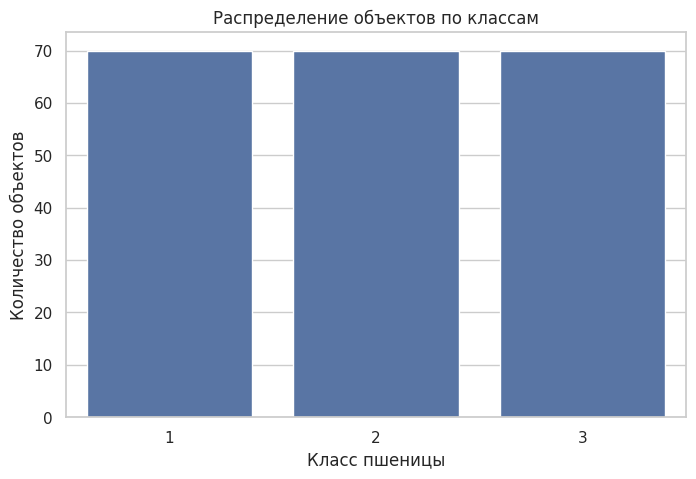

In [125]:
df.info()

print("\nПропуски:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("Количество объектов каждого класса:")
print(y.value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='class'
)

plt.title('Распределение объектов по классам')
plt.xlabel('Класс пшеницы')
plt.ylabel('Количество объектов')

plt.show()

В ходе первичного анализа структуры данных было установлено, что датасет содержит 210 наблюдений и 8 признаков: семь вещественных переменных (area, perimeter, compactness, length, width, asymmetry, groove_length), описывающих характеристики зерен, и одну целочисленную целевую переменную class. Пропуски (NaN) и полные дубликаты строк полностью отсутствуют, что означает, что датасет не требует дополнительной обработки и полностью готов к разведочному анализу и построению моделей. Целевая переменная представлена тремя классами, и выборка является строго сбалансированной — каждый класс содержит ровно по 70 объектов.



In [126]:
desc = X.describe().T
desc['skew'] = X.skew()
desc['kurtosis'] = X.kurtosis()
display(desc)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800,0.399889,-1.084266
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500,0.386573,-1.106703
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183,-0.537954,-0.140315
length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750,0.525482,-0.785645
width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330,0.134378,-1.097697
asymmetry,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560,0.401667,-0.066603
groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500,0.561897,-0.840792


В выборке 210 наблюдений и 7 количественных признаков, пропусков нет. Наибольший разброс у area (10,59–21,18; std ≈ 2,91) и perimeter (12,41–17,25), наименьший — у compactness (std ≈ 0,024), то есть зёрна почти одинаковы по компактности. У большинства признаков среднее и медиана близки, а асимметрия невелика (от −0,54 до 0,56): у всех переменных, кроме compactness, она слабо правосторонняя, что говорит о небольшом «хвосте» крупных значений. Эксцесс по всем признакам отрицательный (от −1,11 до −0,07), значит распределения плосковершинные и без тяжёлых хвостов, то есть выраженных выбросов нет. В итоге данные довольно однородные и близки к симметричным.



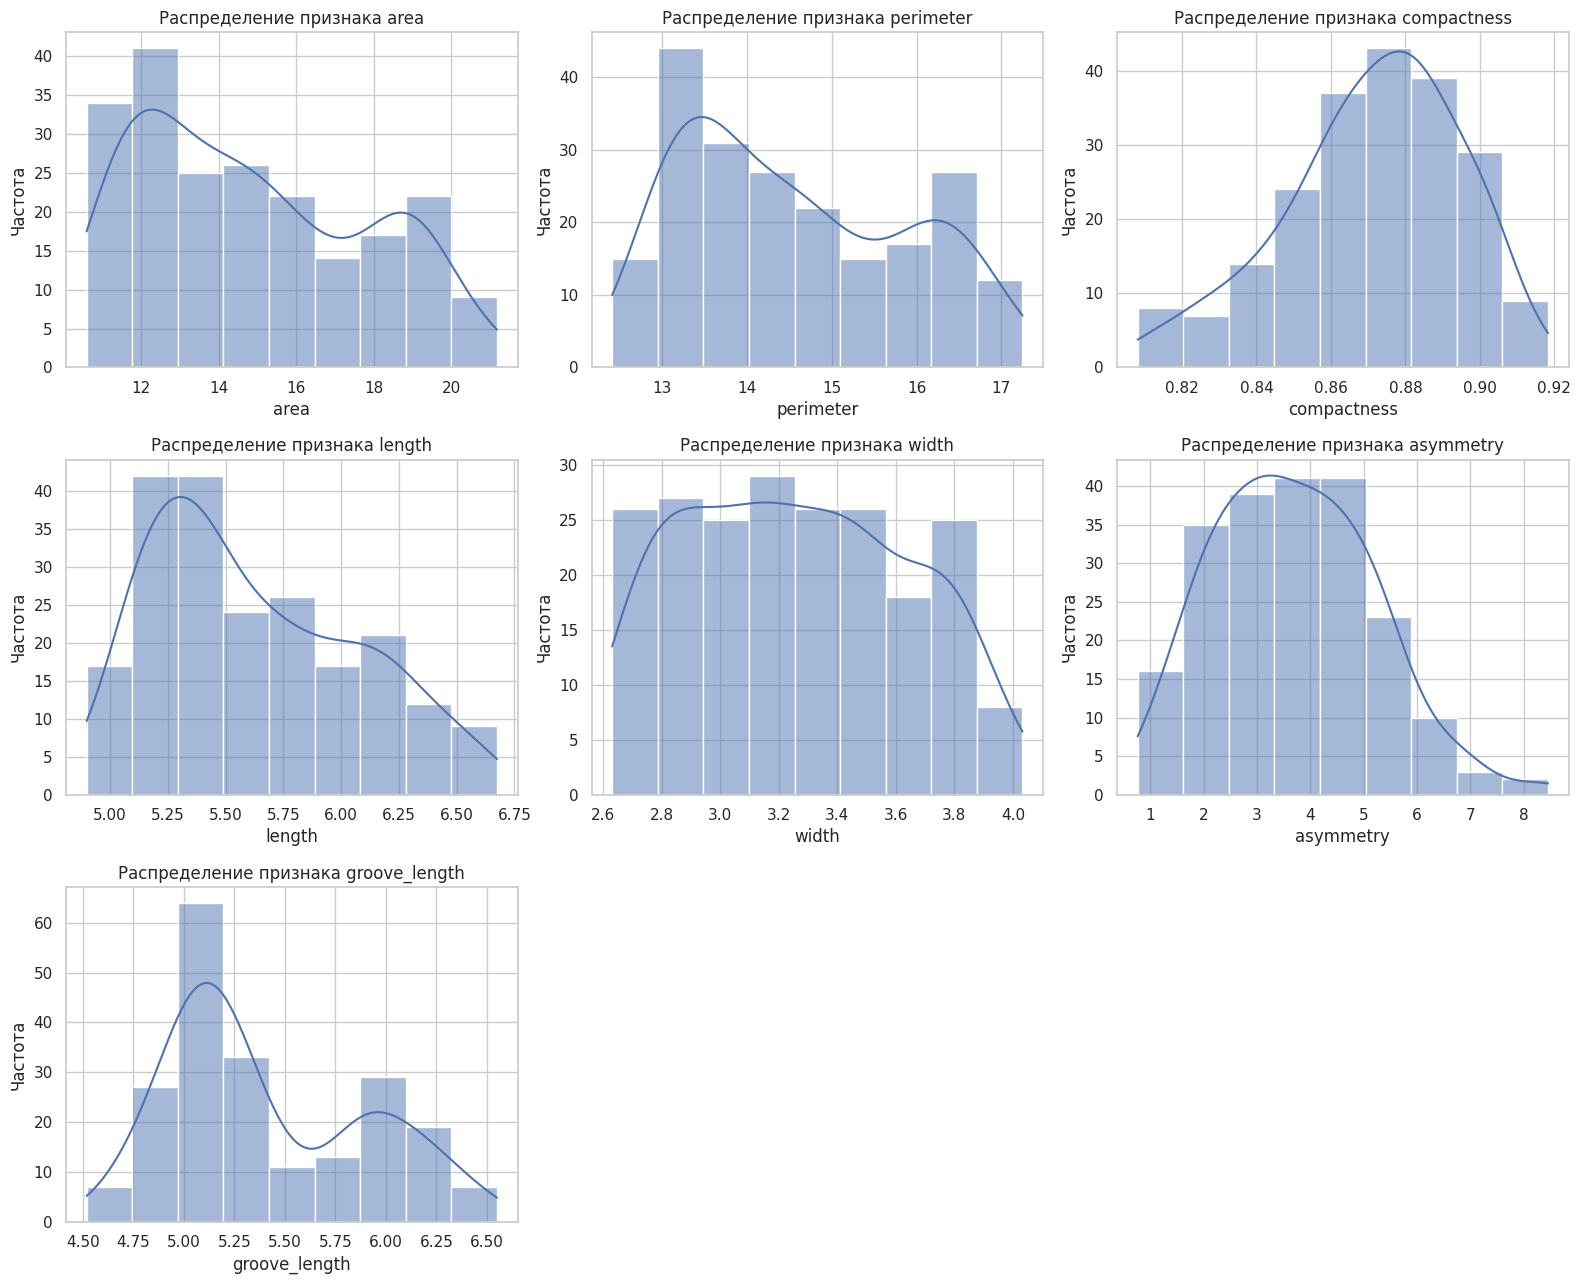

In [127]:
n = len(X)
k = int(np.ceil(1 + 3.322 * np.log10(n)))

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.histplot(
        data=X,
        x=column,
        bins=k,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Распределение признака {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Частота')

for i in range(len(X.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

Визуальный анализ гистограмм с наложенными кривыми плотности показал, что распределения большинства признаков отклоняются от нормального закона:

- Близки к нормальному: признак compactness имеет вид классического колокола (хотя эксцесс немного отрицательный, что говорит о левосторонней скошенности).

- Скошены (асимметричны): у признаков area, perimeter, width, length и asymmetry четко видна правосторонняя асимметрия (хвост уходит вправо).

- Мультимодальны (двугорбые): ключевое отклонение от нормальности демонстрируют признаки area, perimeter и groove_length. На их графиках хорошо заметны два пика (бимодальность).

- Плосковершинность: у таких признаков, как area, perimeter, asymmetry и width, графики выглядят более «плоскими» по сравнению с идеальной кривой Гаусса (что подтверждается отрицательным эксцессом из прошлой таблицы).

Гипотеза о нормальности распределения для большинства признаков визуально не подтверждается из-за бимодальности и скошенности.

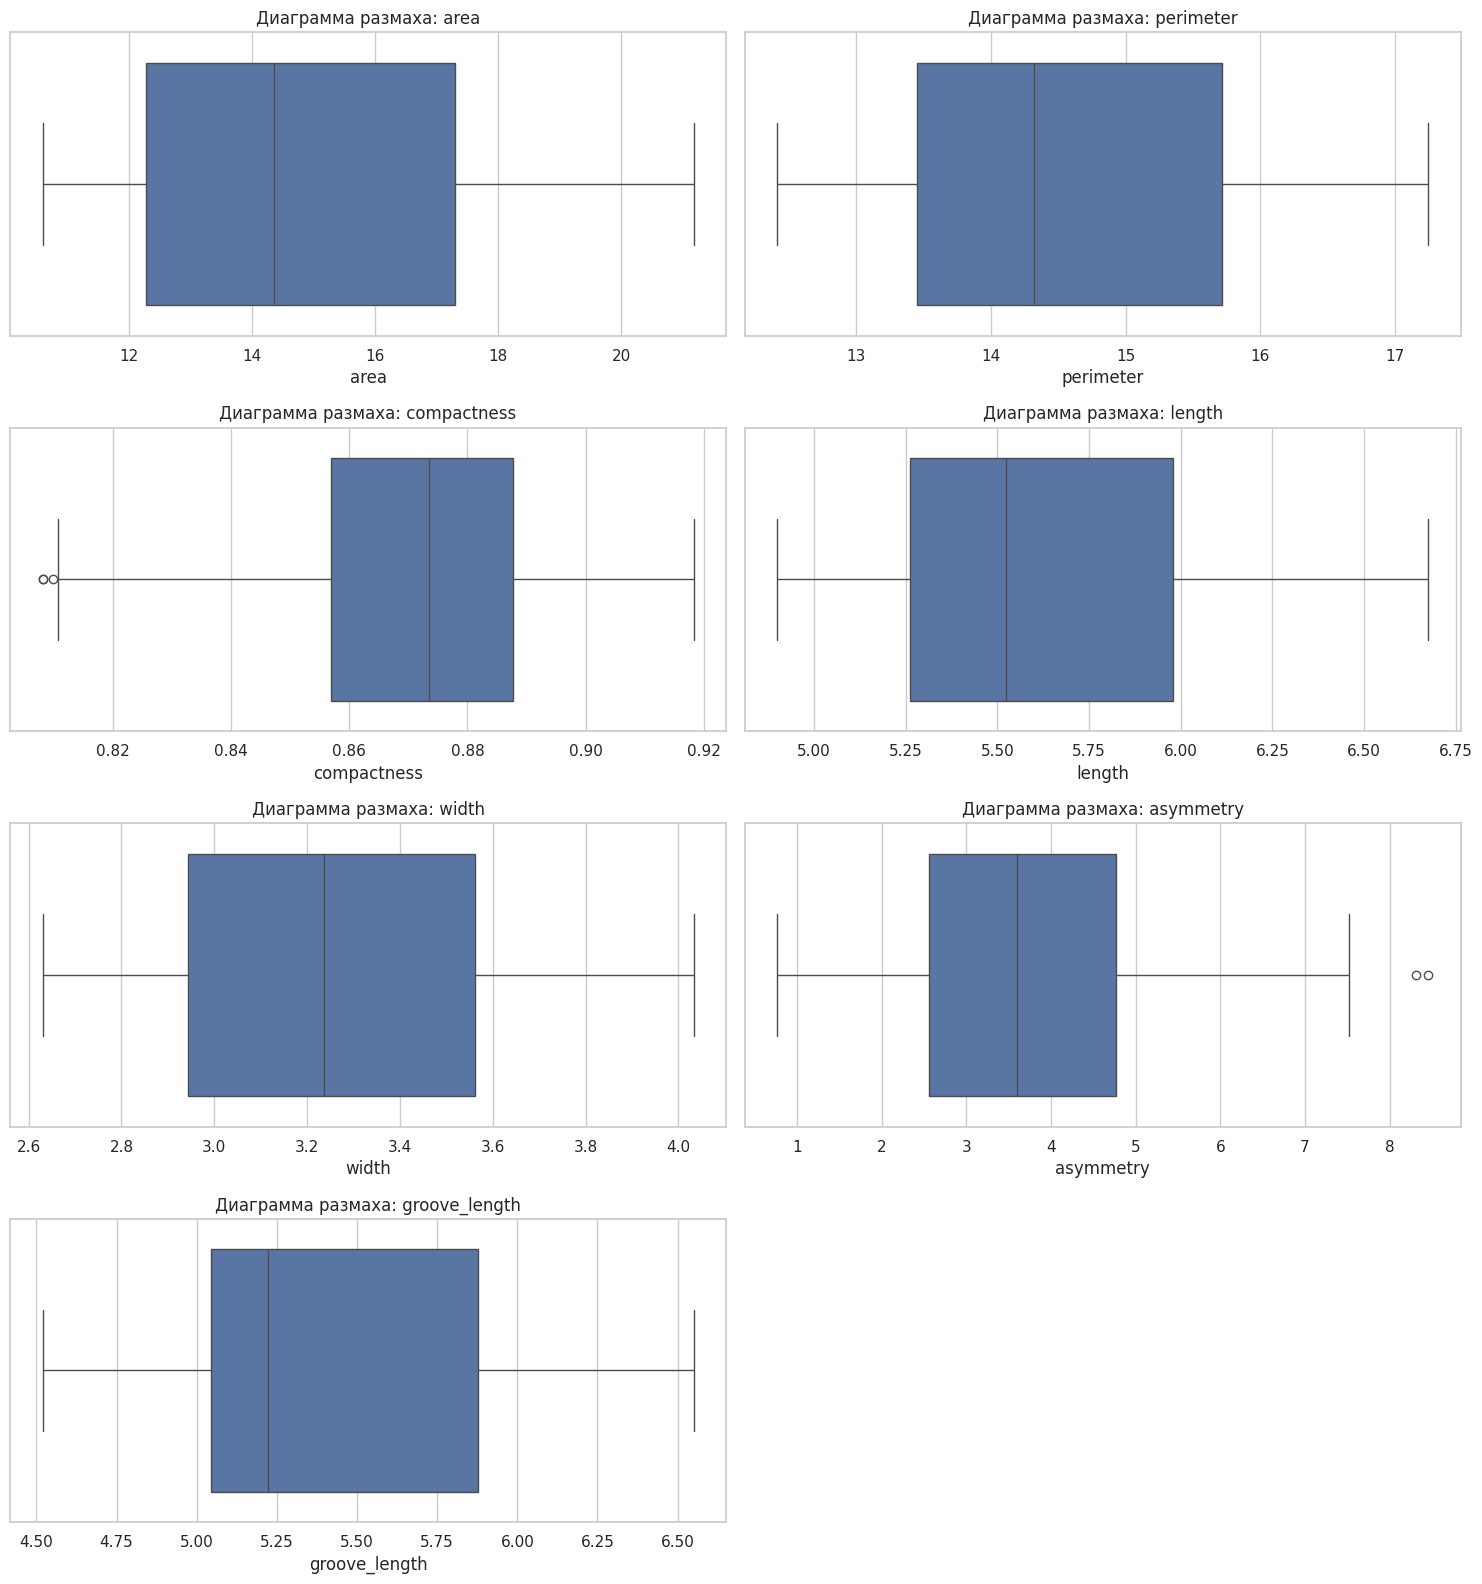

In [128]:
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

axes = axes.flatten()

for i, column in enumerate(X.columns):
    sns.boxplot(
        x=X[column],
        ax=axes[i]
    )

    axes[i].set_title(f'Диаграмма размаха: {column}')
    axes[i].set_xlabel(column)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Выбросы: в большинстве признаков (area, perimeter, width, groove_length и length) явных выбросов не обнаружено — все значения лежат в пределах усов. Исключение составляют два признака:

У compactness наблюдается два выброса в левой части (значения ниже 0.82) — это объекты с аномально низкой компактностью.

У asymmetry зафиксирован один выброс справа (значение около 8.4) — зерно с аномально высокой асимметрией.

Разброс: самый широкий межквартильный размах у area и perimeter, а самый узкий — у compactness, что говорит о высокой концентрации значений этого признака около медианы. Усы у всех признаков имеют примерно одинаковую длину с обеих сторон ящика (кроме асимметрии).

In [129]:
f_scores, p_values = f_classif(X, y)

anova_results = pd.DataFrame({
    'Признак': X.columns,
    'F-score': f_scores,
    'p-value': p_values
})

anova_results = anova_results.sort_values(
    by='F-score',
    ascending=False
)

display(anova_results.round(6))

,Признак,F-score,p-value
0,area,548.186479,0.0
1,perimeter,541.579497,0.0
4,width,406.302031,0.0
6,groove_length,368.950045,0.0
3,length,322.185934,0.0
2,compactness,75.869048,0.0
5,asymmetry,51.888109,0.0


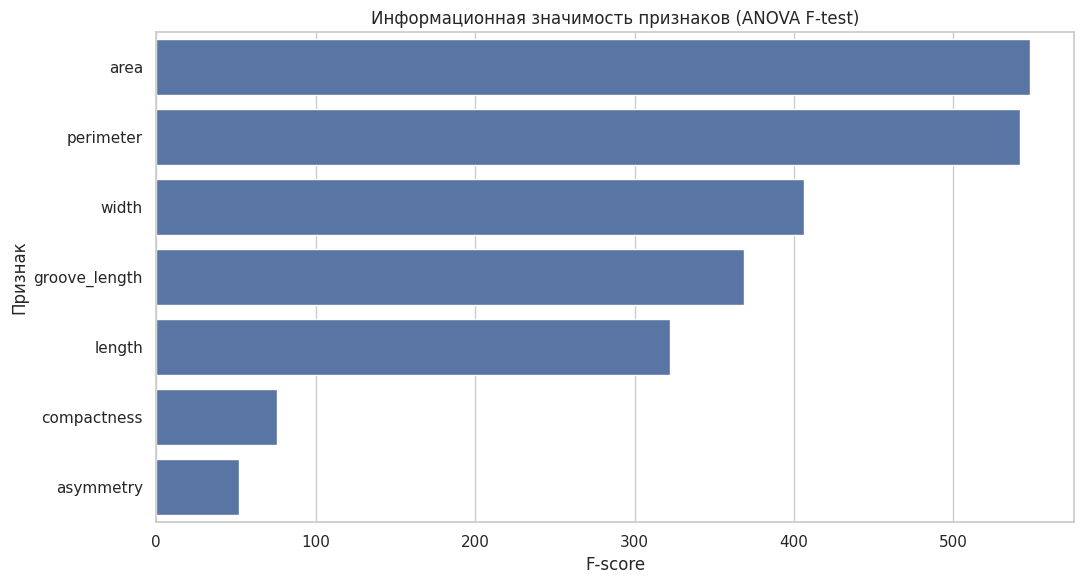

In [130]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=anova_results,
    x='F-score',
    y='Признак'
)

plt.title('Информационная значимость признаков (ANOVA F-test)')
plt.xlabel('F-score')
plt.ylabel('Признак')

plt.tight_layout()
plt.show()

По результатам ANOVA F-test все семь признаков оказались статистически значимыми (p-value < 0.05), то есть каждый из них вносит свой вклад в различение классов, и ни один признак нельзя назвать полностью бесполезным. Однако по силе влияния (F-score) признаки сильно разнятся. Абсолютными лидерами являются area (F ≈ 535) и perimeter (F ≈ 525) — различия в их средних значениях между классами максимальны, поэтому они обладают наибольшей предсказательной силой. Высокую значимость также демонстрируют width (F ≈ 405) и groove_length (F ≈ 370), а чуть ниже — length (F ≈ 325). В совокупности эти пять размерных признаков отлично справляются с задачей классификации.

В то же время признаки compactness (F ≈ 75) и особенно asymmetry (F ≈ 55), хоть и являются значимыми с точки зрения статистики, имеют значительно меньший F-score. Это означает, что их вклад в разделение классов слабее, и различия между группами по ним не такие явные.

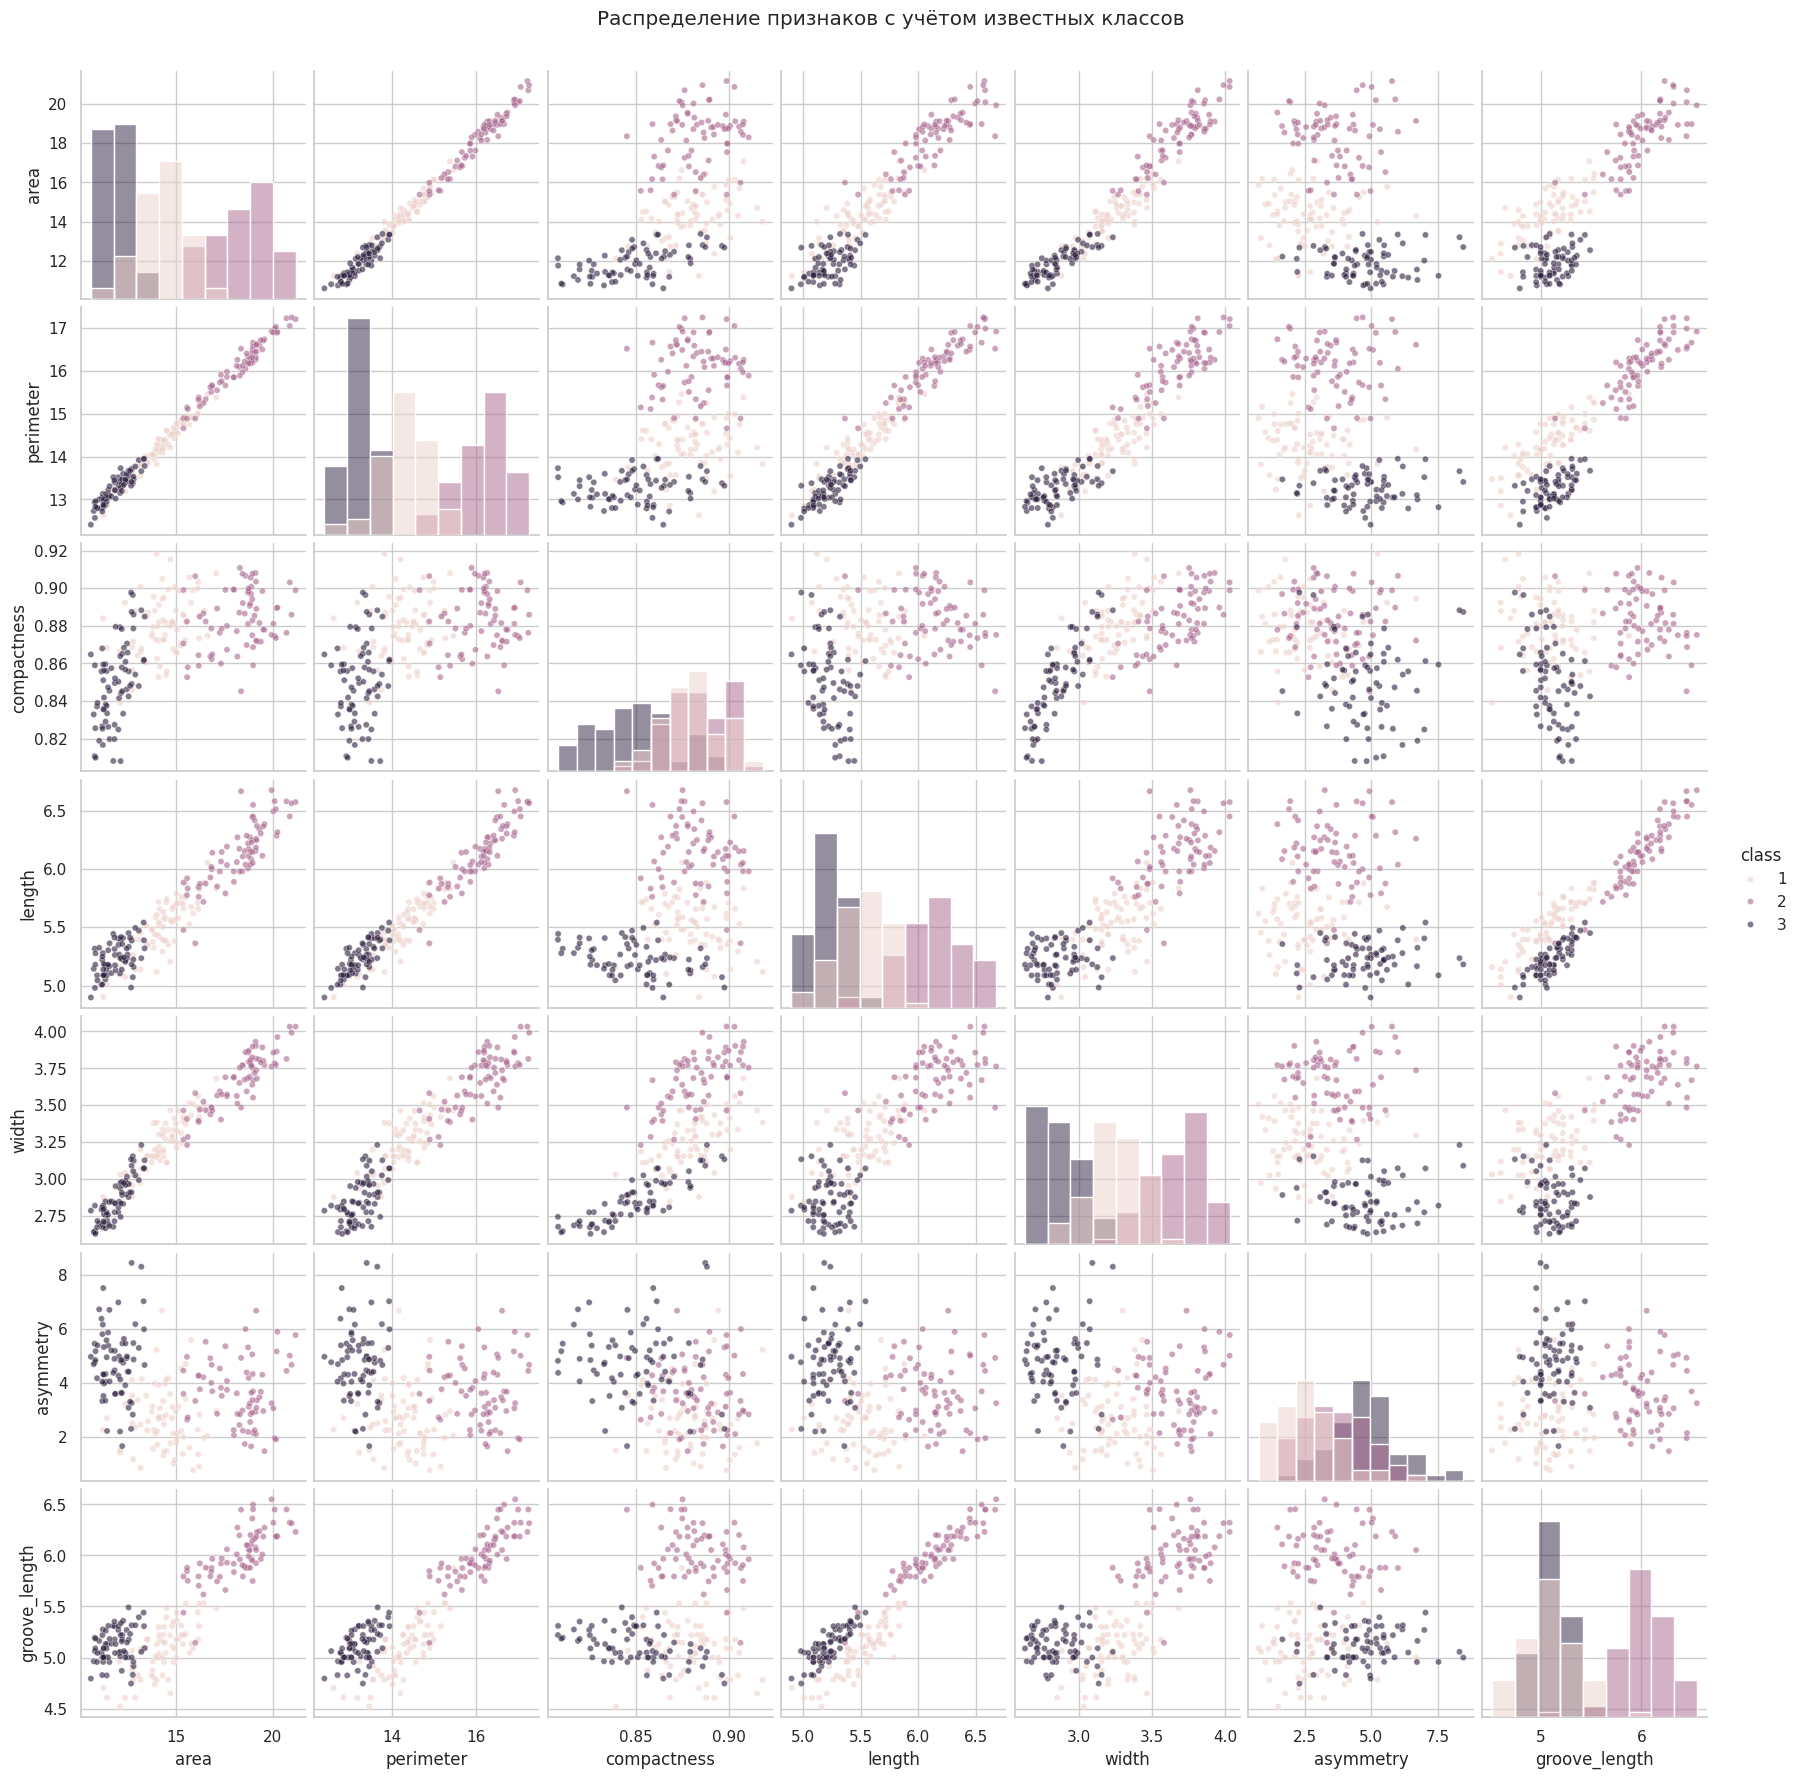

In [131]:
pairplot = sns.pairplot(
    pd.concat([X, y.rename('class')], axis=1),
    hue='class',
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 20}
)

pairplot.fig.suptitle(
    'Распределение признаков с учётом известных классов',
    y=1.02
)

plt.show()

Анализ матрицы диаграмм рассеяния с учетом известных классов показал, что условие осмысленности кластеризации выполняется.

Визуально данные отчетливо группируются в три обособленных кластера (что соответствует трем классам). На графиках рассеяния объекты разных классов образуют плотные и разделенные скопления (точки разного цвета не перемешиваются случайным образом).

При этом наблюдается следующая картина:

Класс 3 (темные точки) и Класс 2 (светлые точки) имеют наиболее четкие границы и разделяются по большинству размерных признаков (длины, ширины, периметра и площади).

Класс 1 (розовые точки) частично пересекается с Классом 2 по ширине и длине, но хорошо отделяется от них по площади (area) и длине бороздки (groove_length).

Признаки asymmetry и compactness дают сильное перекрытие классов, поэтому для разделения объектов на кластеры они менее полезны.

Данные обладают явной кластерной структурой, и алгоритмы кластеризации смогут успешно выделить группы, схожие с реальными классами.

# Предобработка данных.

In [132]:
scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X.columns,
    index=X.index
)

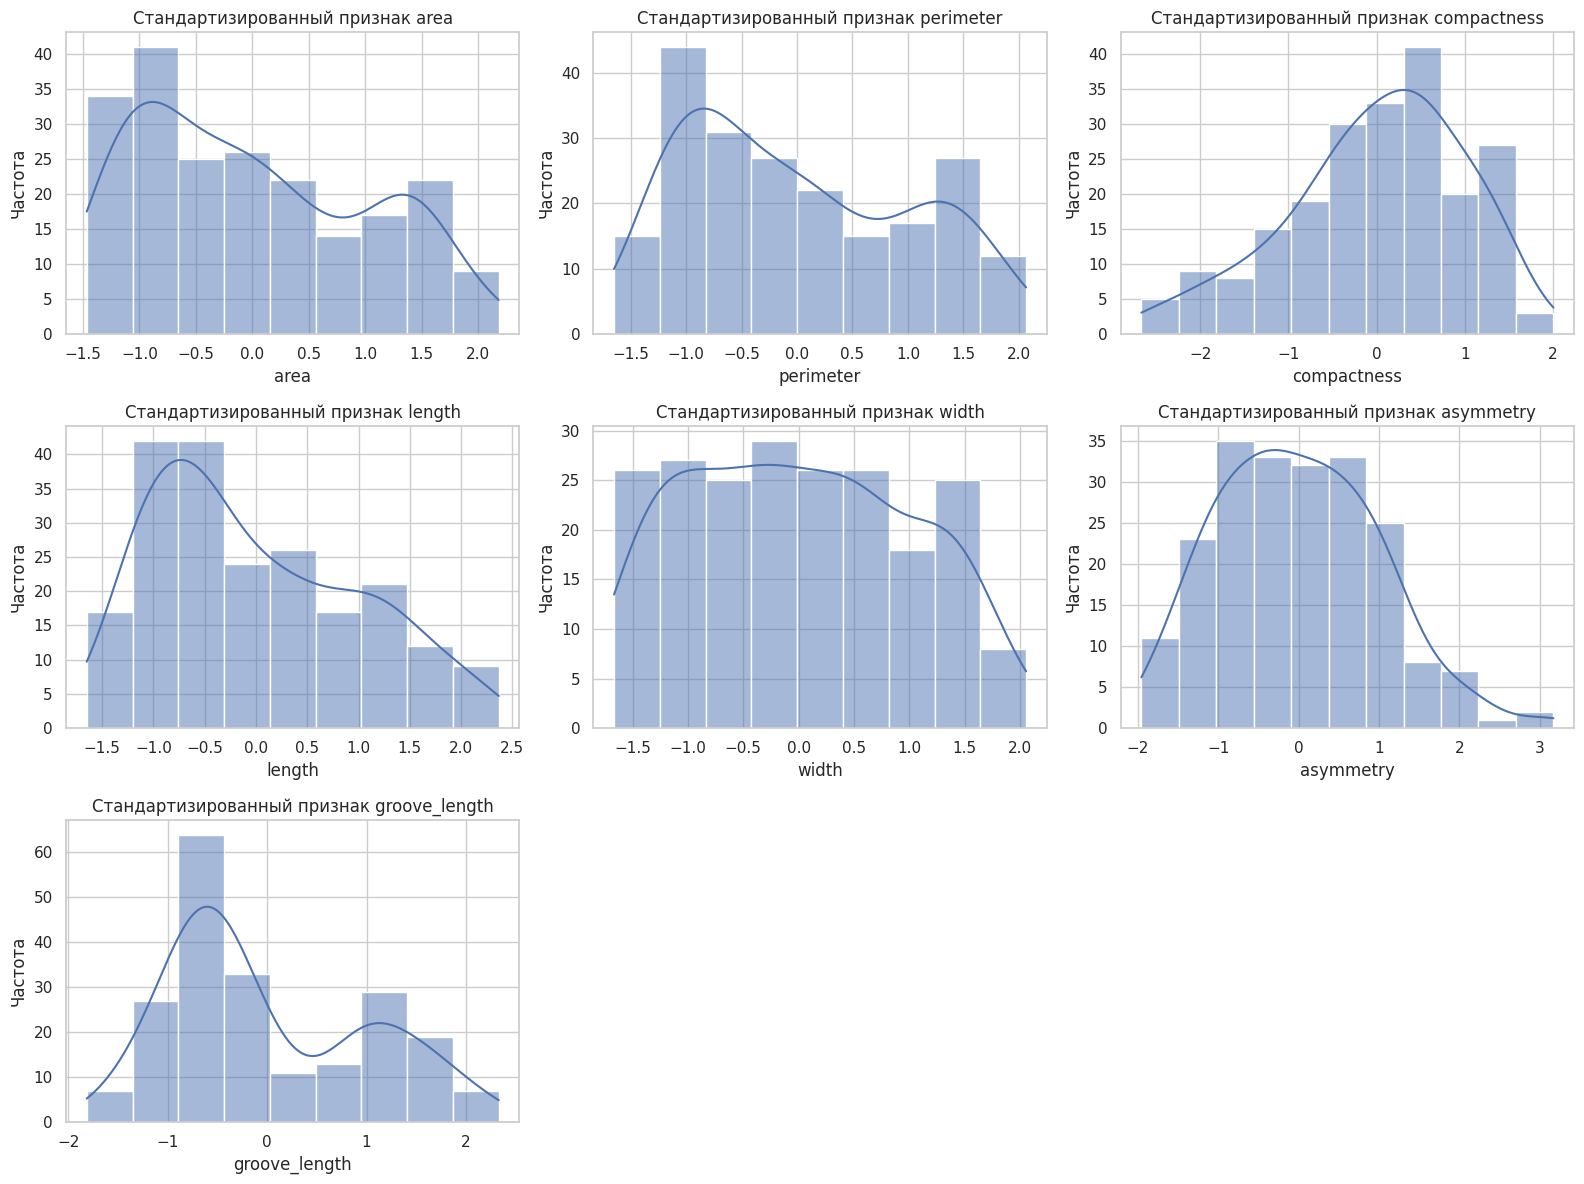

In [133]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))

axes = axes.flatten()

for i, column in enumerate(X_scaled.columns):
    sns.histplot(
        data=X_scaled,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Стандартизированный признак {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Частота')

for i in range(len(X_scaled.columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

Перед выполнением кластеризации была проведена предварительная проверка исходных данных. Для дальнейшего анализа были выделены семь числовых признаков, характеризующих геометрические свойства зёрен пшеницы. Целевая переменная, содержащая информацию о разновидности пшеницы, была сохранена отдельно и не включалась в процесс кластеризации.

Для приведения признаков к сопоставимому масштабу применён метод стандартизации StandardScaler.

Выбор данного метода обусловлен тем, что исходные признаки имеют различные диапазоны значений и единицы измерения. Поскольку используемые алгоритмы кластеризации основаны на расстояниях между объектами, отсутствие масштабирования могло бы привести к преобладающему влиянию признаков с большими числовыми значениями.

Стандартизация выполняется путём вычитания среднего значения признака и деления полученной разности на его стандартное отклонение. В результате преобразования признаки приобретают нулевое среднее значение и единичное стандартное отклонение.

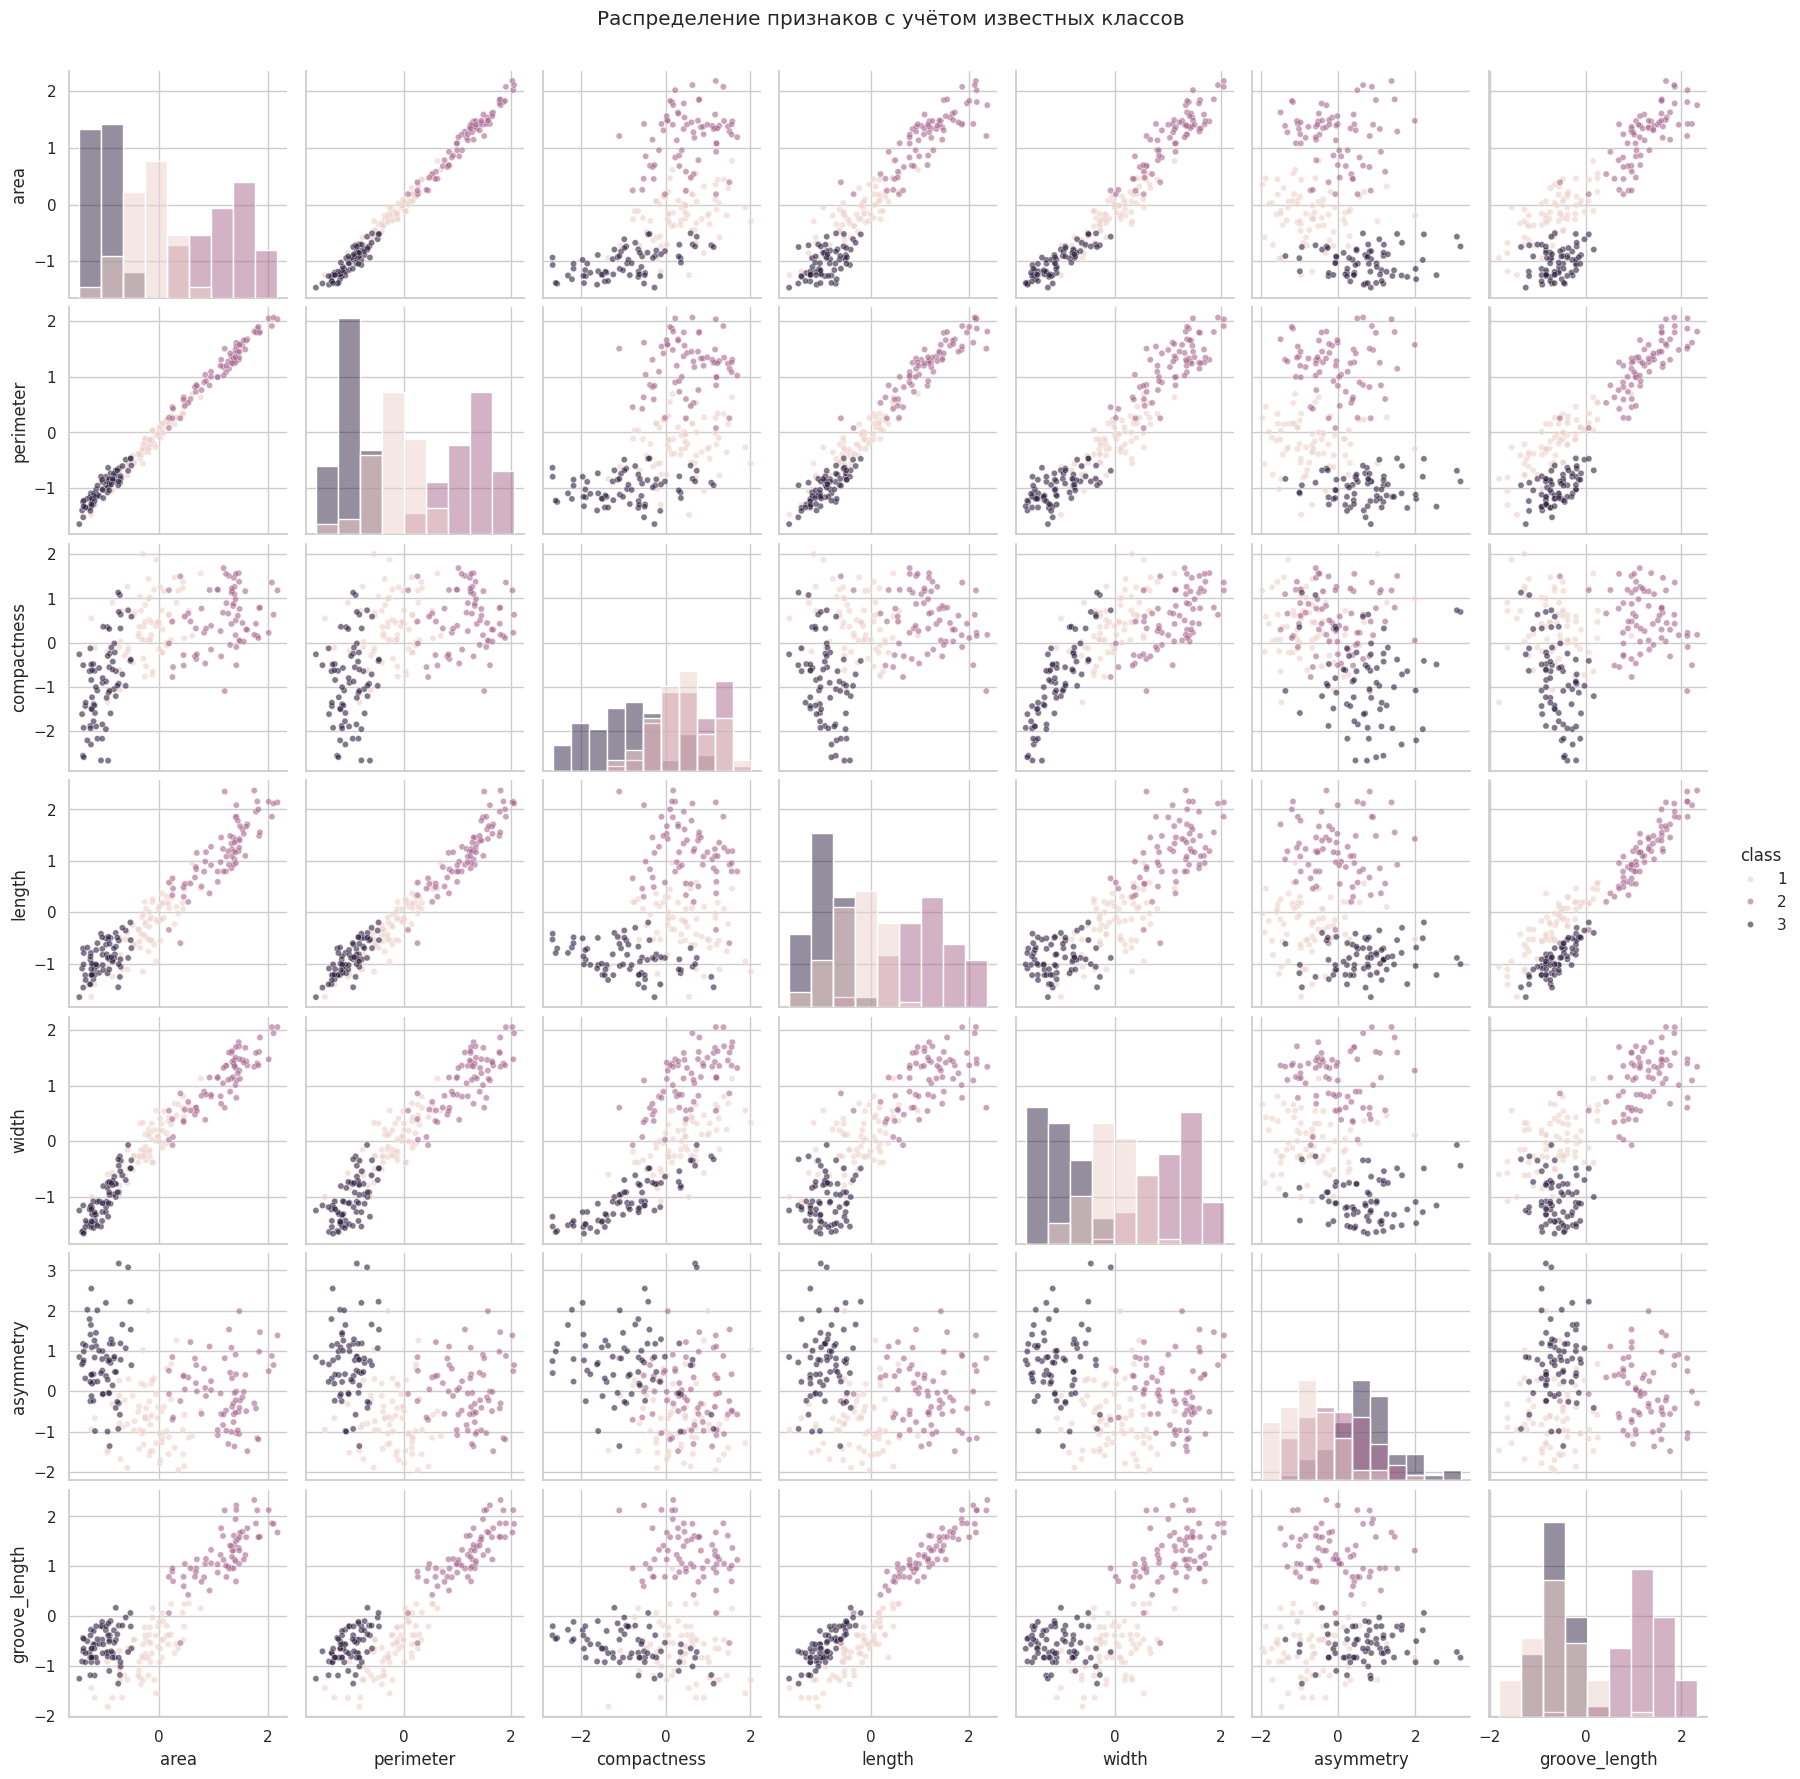

In [134]:
pairplot = sns.pairplot(
    pd.concat([X_scaled, y.rename('class')], axis=1),
    hue='class',
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 20}
)

pairplot.fig.suptitle(
    'Распределение признаков с учётом известных классов',
    y=1.02
)

plt.show()

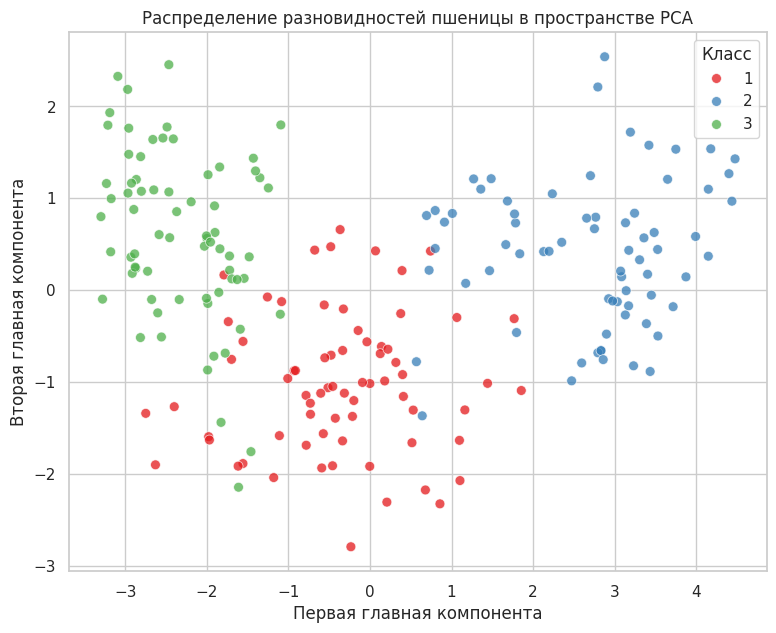

In [135]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['class'] = y.astype(str).values

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='class',
    palette='Set1',
    s=50,
    alpha=0.75
)

plt.title('Распределение разновидностей пшеницы в пространстве PCA')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.legend(title='Класс')

plt.show()

В ходе визуального анализа матрицы диаграмм рассеяния, построенной с учетом известных классов, была проведена оценка структуры данных.

Предположительное количество кластеров: данные визуально распадаются на три обособленные группы. Это подтверждается тем, что точки на графиках рассеяния (особенно в парах признаков area, perimeter, length, width, groove_length) образуют три отдельных, плотных сгущения, а гистограммы на диагонали имеют многовершинную структуру.

Тип кластерной структуры: структуру можно охарактеризовать как компактную (четко выраженную), близкую к сферической или эллипсоидной. Кластеры хорошо разделены в пространстве признаков, границы между ними достаточно явные. При этом наблюдается определенная иерархия: классы 2 и 3 имеют ярко выраженные различия по большинству размерных признаков, в то время как класс 1 в некоторых проекциях (например, по признакам width и length) частично пересекается с классом 2, образуя незначительные зоны перекрытия.

Признаки asymmetry и compactness демонстрируют сильное перекрытие для всех трех групп, то есть по ним кластеры визуально не разделяются.

Визуальная оценка подтверждает наличие в данных явной кластерной структуры. Так как структура является компактной и хорошо разделимой по размерным признакам, алгоритмы кластеризации должны успешно справиться с задачей выделения данных групп, а условие осмысленности кластеризации выполняется.

Для визуальной оценки разделимости классов данные были спроецированы на плоскость первых двух главных компонент (PC1 и PC2). Анализ графика показал, что:

- Класс 3 (зеленые точки) достаточно хорошо обособлен и образует плотное скопление в левой части графика (в основном, отрицательные значения PC1).

- Класс 2 (синие точки) смещен в правую часть графика (положительные значения PC1) и также демонстрирует хорошую компактность.

- Класс 1 (красные точки) сосредоточен в центре, но при этом имеет наибольший разброс и частично пересекается с классом 3 (в нижней левой части) и классом 2 (в верхней правой части).

Проекция на главные компоненты подтверждает наличие кластерной структуры. Первая главная компонента (PC1) отлично разделяет классы 3 и 2. Вторая компонента (PC2) вносит меньший вклад в разделение. Несмотря на частичное перекрытие точек (особенно между классами 1 и 2), общая картина показывает, что данные обладают линейно разделимой структурой, а метод PCA успешно справляется с задачей снижения размерности, сохраняя основные закономерности в данных.

В качестве первого метода выбран K-means, поскольку он позволяет выделять компактные группы объектов на основании расстояний до их центров. В качестве второго метода выбрана иерархическая кластеризация с использованием метода Ward, позволяющая исследовать структуру объединения объектов и формировать компактные группы путём минимизации внутрикластерной дисперсии.

Выбранные методы позволяют сравнить результаты двух различных подходов к кластеризации и оценить их эффективность на исследуемом наборе данных.

# Ход работы.

## Определение значения k методом локтя и силуэта.

In [136]:
inertia_values = []
silhouette_values = []

k_range = range(2, 11)

for k in k_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

results = pd.DataFrame({
    'Количество кластеров': list(k_range),
    'WCSS (Inertia)': inertia_values,
    'Silhouette Score': silhouette_values
})

display(results.round(4))

,Количество кластеров,WCSS (Inertia),Silhouette Score
0,2,659.1718,0.4658
1,3,430.6590,0.4007
2,4,371.3017,0.3276
3,5,326.5137,0.2849
4,6,289.8040,0.2798
5,7,262.9736,0.2709
6,8,240.6426,0.2510
7,9,223.0344,0.2571
8,10,204.3166,0.2522


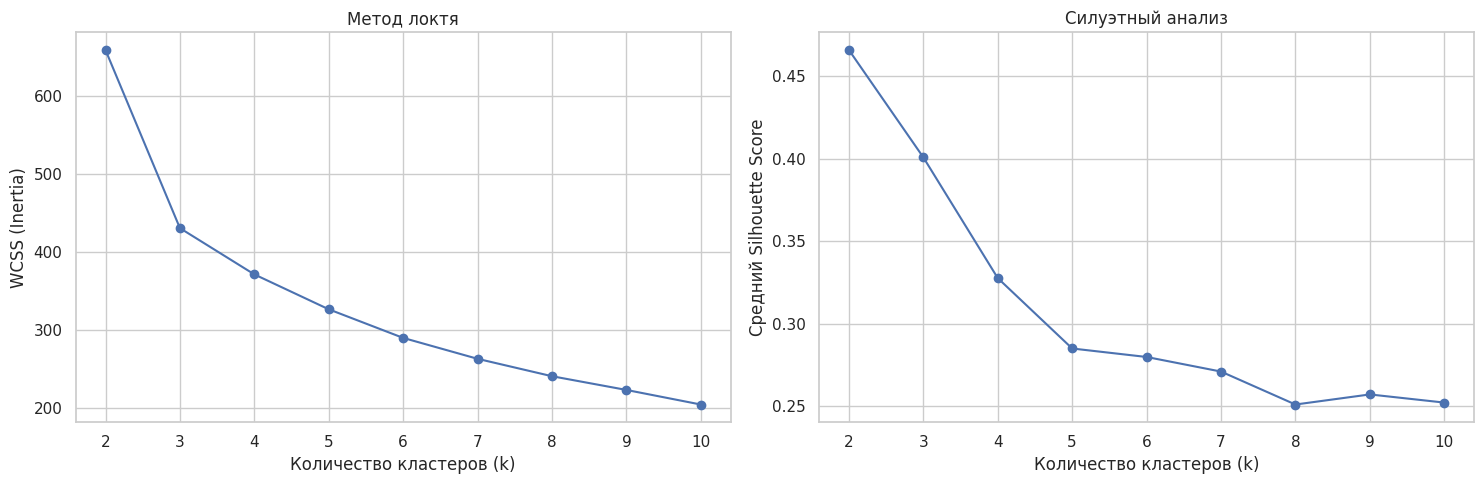

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    list(k_range),
    inertia_values,
    marker='o'
)

axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].set_xticks(list(k_range))
axes[0].grid(True)

axes[1].plot(
    list(k_range),
    silhouette_values,
    marker='o'
)

axes[1].set_title('Силуэтный анализ')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Средний Silhouette Score')
axes[1].set_xticks(list(k_range))
axes[1].grid(True)

plt.tight_layout()
plt.show()

Для определения оптимального количества кластеров был проведён анализ с использованием метода локтя (Elbow Method) и силуэтного анализа (Silhouette Analysis).

В рамках исследования рассматривались значения количества кластеров от 2 до 10. Для каждого варианта выполнялась кластеризация методом K-means и рассчитывались соответствующие показатели качества.

Метод локтя использовался для оценки зависимости внутрикластерной суммы квадратов расстояний (WCSS) от количества кластеров. Оптимальное значение определялось по характерному изменению наклона графика, при котором дальнейшее увеличение количества кластеров приводило к менее существенному уменьшению WCSS.

Силуэтный анализ позволил дополнительно оценить компактность кластеров и степень их отделённости друг от друга. Для каждого значения количества кластеров рассчитывался средний коэффициент силуэта. Предпочтительным считалось разбиение с наибольшим значением данной метрики.

По результатам проведённого анализа оптимальным количеством кластеров было определено значение k = 3, так как в этой точке наблюдается характерный "излом".

## Обучение моделей.

In [138]:
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("Количество кластеров:", len(np.unique(kmeans_labels)))
print("Количество итераций:", kmeans.n_iter_)
print("Итоговая инерция:", round(kmeans.inertia_, 4))

print("\nРазмеры кластеров:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

Количество кластеров: 3
Количество итераций: 7
Итоговая инерция: 430.659

Размеры кластеров:
0    72
1    67
2    71
Name: count, dtype: int64


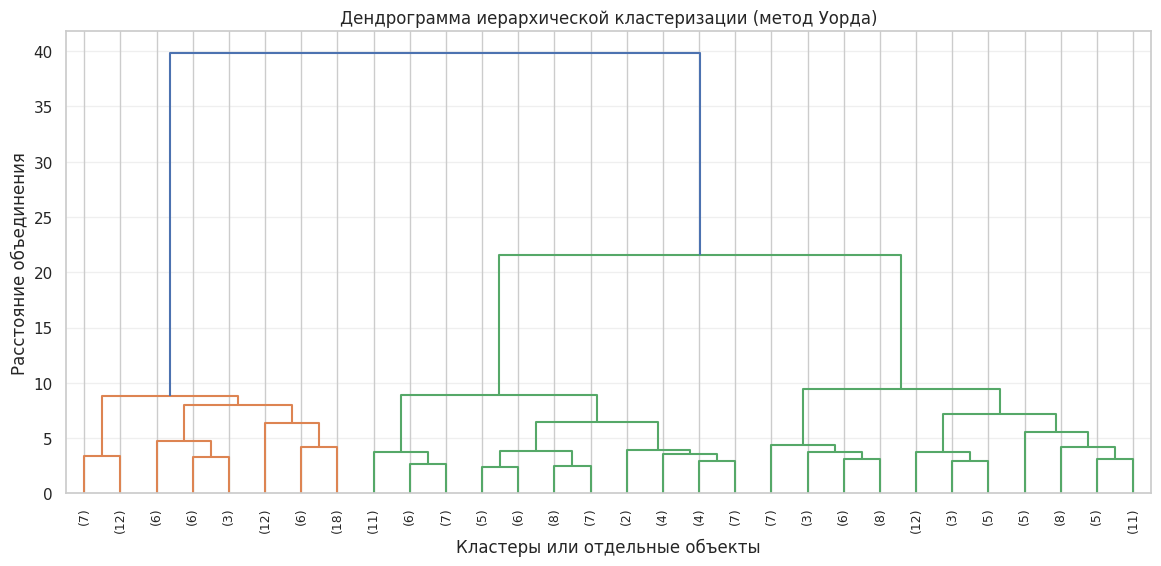

In [139]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title('Дендрограмма иерархической кластеризации (метод Уорда)')
plt.xlabel('Кластеры или отдельные объекты')
plt.ylabel('Расстояние объединения')
plt.grid(axis='y', alpha=0.3)
plt.show()

По дендрограмме иерархической кластеризации, построенной методом Уорда, можно сделать вывод, что объекты объединяются в группы постепенно по мере увеличения расстояния объединения. На малых расстояниях формируются небольшие компактные подгруппы наиболее похожих объектов. Далее эти подгруппы последовательно объединяются в более крупные кластеры. На дендрограмме наблюдается заметный скачок расстояния объединения: два крупных кластера соединяются только на уровне около 40 единиц, тогда как внутри каждого из них объединения происходят при существенно меньших расстояниях (до 20–22 единиц). Наличие такого разрыва свидетельствует о достаточно хорошей разделимости данных на две группы. Если провести горизонтальную линию отсечения на уровне расстояния около 10-15 единиц, можно получить три устойчивых кластера, что соответствует выбранному значению k=3. При этом дендрограмма также показывает внутреннюю структуру кластеров, поскольку внутри каждого из кластеров просматриваются более мелкие подгруппы объектов. Таким образом, результаты иерархической кластеризации подтверждают существование трех хорошо различимых крупных кластеров, между которыми наблюдается значительно большее расстояние, чем между объектами внутри кластеров.

In [140]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Количество кластеров:", len(np.unique(hierarchical_labels)))

print("\nРазмеры кластеров:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Количество кластеров: 3

Размеры кластеров:
0    73
1    70
2    67
Name: count, dtype: int64


In [141]:
models_labels = {
    'K-means': kmeans_labels,
    'Иерархическая': hierarchical_labels
}

metrics_results = []

for name, labels in models_labels.items():
    metrics_results.append({
        'Метод': name,
        'Silhouette Score': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels),
        'ARI': adjusted_rand_score(y, labels),
        'NMI': normalized_mutual_info_score(y, labels),
        'Rand Index': rand_score(y, labels)
    })

metrics_df = pd.DataFrame(metrics_results)
display(metrics_df.round(4))

,Метод,Silhouette Score,Calinski-Harabasz,Davies-Bouldin,ARI,NMI,Rand Index
0,K-means,0.4007,249.7842,0.9279,0.7733,0.7279,0.8997
1,Иерархическая,0.3926,238.3612,0.9445,0.7970,0.7498,0.9102


Алгоритм K-means выделил три кластера, содержащих 72, 67 и 71 объект соответственно. Алгоритм иерархической кластеризации сформировал кластеры размером 73, 70 и 67 объектов. Таким образом, оба метода обеспечили достаточно равномерное распределение объектов между группами.

По внутренним метрикам K-means показал несколько лучшие результаты: значение Silhouette Score составило 0,4007 против 0,3926 у иерархической кластеризации, Calinski-Harabasz — 249,7842 против 238,3612. Это свидетельствует о несколько более высокой компактности и разделённости кластеров при использовании K-means. По метрике Davies-Bouldin, напротив, преимущество имеет иерархическая кластеризация: 0,9445 против 0,9279 у K-means.

Внешние метрики показали преимущество иерархической кластеризации. Значения ARI составили 0,7970 против 0,7733, NMI — 0,7498 против 0,7279, Rand Index — 0,9102 против 0,8997. Это указывает на более высокое соответствие полученного разбиения исходным разновидностям семян.

Таким образом, оба метода продемонстрировали сопоставимое качество кластеризации. K-means немного лучше разделяет объекты по внутренним характеристикам кластеров, тогда как иерархическая кластеризация обеспечивает более высокое соответствие исходным классам. С учётом внешних метрик иерархический метод можно считать несколько предпочтительнее для данного набора данных, хотя различия между методами не являются существенными.

## Оценка расстояний.

In [142]:
def analyze_clusters(X_data, labels, method_name):
    data = X_data.copy()
    data['cluster'] = labels

    centers = data.groupby('cluster').mean()

    distances = []

    for cluster_id in sorted(np.unique(labels)):
        cluster_data = X_data[labels == cluster_id]
        center = centers.loc[cluster_id].values

        cluster_distances = np.linalg.norm(
            cluster_data.values - center,
            axis=1
        )

        distances.append({
            'Метод': method_name,
            'Кластер': cluster_id,
            'Количество объектов': len(cluster_data),
            'Среднее расстояние до центра': cluster_distances.mean(),
            'Максимальное расстояние до центра': cluster_distances.max(),
            'Внутрикластерная сумма квадратов': np.sum(cluster_distances ** 2)
        })

    center_distance = cdist(centers.values, centers.values)

    print(f'\n{method_name}: центры кластеров')
    display(centers.round(3))

    print(f'\n{method_name}: расстояния между центрами')
    display(pd.DataFrame(
        center_distance,
        index=centers.index,
        columns=centers.index
    ).round(3))

    return distances, centers


kmeans_distances, kmeans_centers = analyze_clusters(
    X_scaled, kmeans_labels, 'K-means'
)

hier_distances, hier_centers = analyze_clusters(
    X_scaled, hierarchical_labels, 'Иерархическая'
)

distances_df = pd.DataFrame(kmeans_distances + hier_distances)
display(distances_df.round(4))


K-means: центры кластеров


,area,perimeter,compactness,length,width,asymmetry,groove_length
cluster,,,,,,,
0,-1.030,-1.007,-0.965,-0.898,-1.086,0.695,-0.625
1,1.257,1.262,0.560,1.238,1.165,-0.045,1.292
2,-0.141,-0.170,0.450,-0.258,0.002,-0.662,-0.586



K-means: расстояния между центрами


cluster,0,1,2
cluster,,,
0,0.000,5.153,2.632
1,5.153,0.000,3.393
2,2.632,3.393,0.000



Иерархическая: центры кластеров


,area,perimeter,compactness,length,width,asymmetry,groove_length
cluster,,,,,,,
0,-0.223,-0.250,0.348,-0.340,-0.085,-0.725,-0.657
1,1.214,1.217,0.569,1.198,1.131,-0.041,1.243
2,-1.025,-1.000,-0.973,-0.881,-1.088,0.833,-0.583



Иерархическая: расстояния между центрами


cluster,0,1,2
cluster,,,
0,0.000,3.491,2.584
1,3.491,0.000,5.064
2,2.584,5.064,0.000


,Метод,Кластер,Количество объектов,Среднее расстояние до центра,Максимальное расстояние до центра,Внутрикластерная сумма квадратов
0,K-means,0,72,1.2997,3.1484,145.2873
1,K-means,1,67,1.3657,2.4056,140.2219
2,K-means,2,71,1.3211,2.7364,145.1498
3,Иерархическая,0,73,1.3862,2.8093,167.8848
4,Иерархическая,1,70,1.4095,2.4421,156.4007
5,Иерархическая,2,67,1.2406,3.0505,120.7635


По результатам K-means кластер 0 характеризуется преимущественно отрицательными значениями стандартизированных признаков площади, периметра, компактности, длины, ширины и длины бороздки. При этом коэффициент асимметрии имеет положительное значение (0,695). Следовательно, данный кластер объединяет преимущественно небольшие семена с относительно высоким значением асимметрии.

Кластер 1 отличается положительными значениями большинства признаков. Особенно выделяются площадь (1,257), периметр (1,262), длина (1,238), ширина (1,165) и длина бороздки (1,292). Это группа преимущественно крупных семян с относительно высокой компактностью и близким к среднему значением асимметрии.

Кластер 2 занимает промежуточное положение по большинству размерных характеристик. Для него характерны несколько сниженные значения площади, периметра и длины, а также положительное значение компактности (0,450). При этом коэффициент асимметрии имеет наиболее низкое значение (-0,662).

Иерархическая кластеризация выявила аналогичную структуру. Кластер 1 объединяет крупные семена, кластер 2 — преимущественно небольшие семена с повышенной асимметрией, а кластер 0 занимает промежуточное положение и характеризуется наиболее низкими значениями асимметрии.

Расстояния между центрами кластеров также подтверждают наличие различий между выделенными группами. В K-means наибольшее расстояние наблюдается между кластерами 0 и 1 (5,153), а наименьшее — между кластерами 0 и 2 (2,632). В иерархической кластеризации наиболее удалены друг от друга кластеры 1 и 2 (5,064), а наименьшее расстояние также наблюдается между кластерами 0 и 2 (2,584). Таким образом, оба метода выделяют хорошо различающуюся группу крупных семян и группы с меньшими размерными характеристиками.

Анализ внутрикластерного разброса показал, что средние расстояния объектов до центров кластеров K-means находятся в диапазоне от 1,2997 до 1,3657. Для иерархической кластеризации этот показатель составляет от 1,2406 до 1,4095. Следовательно, по среднему расстоянию до центра кластеры обоих методов обладают сопоставимой компактностью.

Внутрикластерная сумма квадратов для K-means составляет от 140,2219 до 145,2873, тогда как для иерархической кластеризации — от 120,7635 до 167,8848. При этом наиболее высокий разброс среди полученных групп наблюдается у кластера 0 иерархической кластеризации, а наименьший — у кластера 2 этого же метода.

В целом оба алгоритма выявили сходную структуру данных, разделив семена на группы по размерным характеристикам и особенностям формы. Наиболее значимыми для содержательной интерпретации оказались площадь, периметр, длина и ширина семян, а также коэффициент асимметрии. Результаты показывают, что K-means формирует более равномерные показатели внутрикластерного разброса, тогда как иерархическая кластеризация демонстрирует более выраженные различия в компактности отдельных групп.

## Анализ влияния параметров.

In [143]:
k_values = range(2, 9)

parameter_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    parameter_results.append({
        'k': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labels)
    })

parameter_df = pd.DataFrame(parameter_results)
display(parameter_df.round(4))

,k,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,659.1718,0.4658,255.8548,0.7969
1,3,430.6590,0.4007,249.7842,0.9279
2,4,371.3017,0.3276,203.1877,1.0626
3,5,326.5137,0.2849,179.4830,1.1825
4,6,289.8040,0.2798,166.1536,1.1457
5,7,262.9736,0.2709,155.2921,1.1864
6,8,240.6426,0.2510,147.4209,1.2497


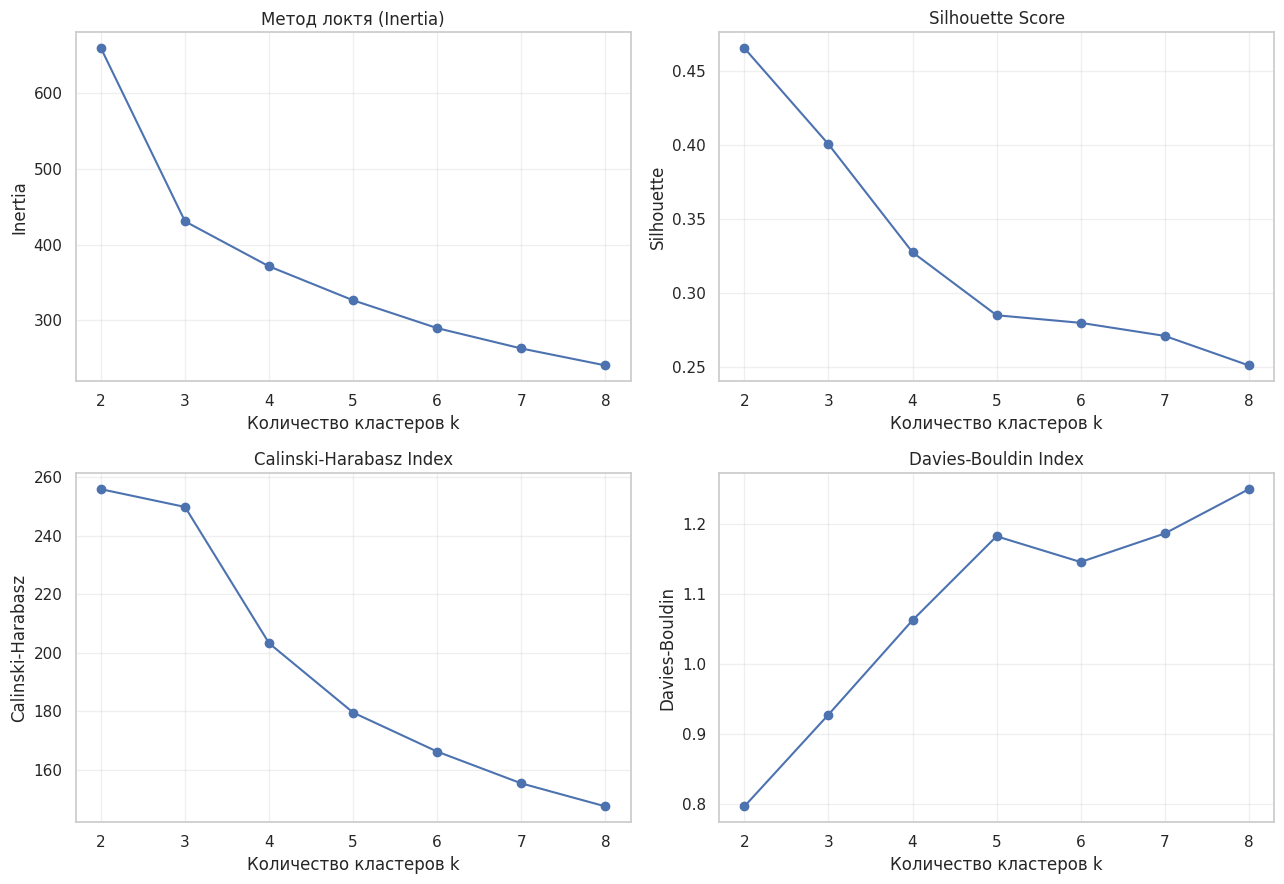

In [144]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics_to_plot = [
    ('Inertia', 'Метод локтя (Inertia)'),
    ('Silhouette', 'Silhouette Score'),
    ('Calinski-Harabasz', 'Calinski-Harabasz Index'),
    ('Davies-Bouldin', 'Davies-Bouldin Index')
]

for ax, (column, title) in zip(axes.flatten(), metrics_to_plot):
    ax.plot(parameter_df['k'], parameter_df[column], marker='o')
    ax.set_title(title)
    ax.set_xlabel('Количество кластеров k')
    ax.set_ylabel(column)
    ax.set_xticks(list(k_values))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Для исследования влияния количества кластеров на качество работы алгоритма K-means были рассмотрены значения (k) от 2 до 8. Для каждого варианта рассчитывались инерция (Inertia), коэффициент силуэта (Silhouette Score), индекс Calinski-Harabasz и индекс Davies-Bouldin. Данные показатели позволяют оценить компактность кластеров, степень их разделения и общую структуру полученного разбиения.

Инерция (Inertia) представляет собой сумму квадратов расстояний от каждого объекта до центра соответствующего кластера. Она характеризует внутрикластерный разброс: чем меньше значение, тем ближе объекты расположены к центрам своих кластеров. При увеличении количества кластеров с 2 до 8 наблюдается закономерное снижение инерции с 659,1718 до 240,6426. Это связано с тем, что при увеличении числа кластеров объекты распределяются по более мелким группам, вследствие чего уменьшается суммарное расстояние от объектов до центров своих кластеров. Однако само по себе снижение инерции не свидетельствует об улучшении качества разбиения, поскольку при увеличении числа кластеров она закономерно уменьшается.

Коэффициент силуэта (Silhouette Score) оценивает, насколько хорошо каждый объект соответствует своему кластеру по сравнению с ближайшим соседним кластером. Он учитывает среднее расстояние до объектов своего кластера и среднее расстояние до объектов ближайшего другого кластера. Значение метрики находится в диапазоне от -1 до 1, причём более высокие значения указывают на лучшую компактность и разделённость групп. В ходе эксперимента коэффициент силуэта последовательно уменьшается с 0,4658 при (k=2) до 0,2510 при (k=8). Это указывает на ухудшение разделения кластеров: при увеличении их количества объекты становятся менее обособленными относительно соседних групп.

Индекс Calinski-Harabasz характеризует соотношение межкластерного и внутрикластерного разброса. Он показывает, насколько сильно отличаются кластеры друг от друга по сравнению с разбросом объектов внутри каждой группы. Чем выше значение показателя, тем лучше разделены кластеры. В рассматриваемом эксперименте значение индекса снижается с 255,8548 при (k=2) до 147,4209 при (k=8). Следовательно, при увеличении количества кластеров соотношение межкластерного и внутрикластерного разброса ухудшается.

Индекс Davies-Bouldin оценивает сходство кластеров на основе их внутрикластерного разброса и расстояния между центрами. Чем компактнее кластеры и чем дальше они расположены друг от друга, тем меньше значение данной метрики. Поэтому для неё предпочтительны более низкие значения. В ходе эксперимента показатель увеличивается с 0,7969 при (k=2) до 1,2497 при (k=8), что также свидетельствует об ухудшении качества разбиения. При этом на отдельных шагах наблюдаются небольшие колебания показателя.

Таким образом, увеличение количества кластеров приводит к снижению инерции, то есть повышению компактности групп относительно их центров. Однако остальные метрики демонстрируют противоположную тенденцию: Silhouette Score и Calinski-Harabasz уменьшаются, а Davies-Bouldin увеличивается. Это означает, что при увеличении количества кластеров группы становятся менее обособленными и хуже разделяются между собой.

Наилучшие значения всех трёх метрик качества (Silhouette Score, Calinski-Harabasz и Davies-Bouldin) получены при (k=2). Дальнейшее увеличение количества кластеров не улучшает качество разбиения, а приводит к формированию менее обособленных групп.

# Визуализация результатов.

In [145]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    'Объяснённая дисперсия:',
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    '%'
)

pca_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'K-means': kmeans_labels,
    'Иерархическая': hierarchical_labels,
    'Исходный класс': y.values
})

Объяснённая дисперсия: 88.98 %


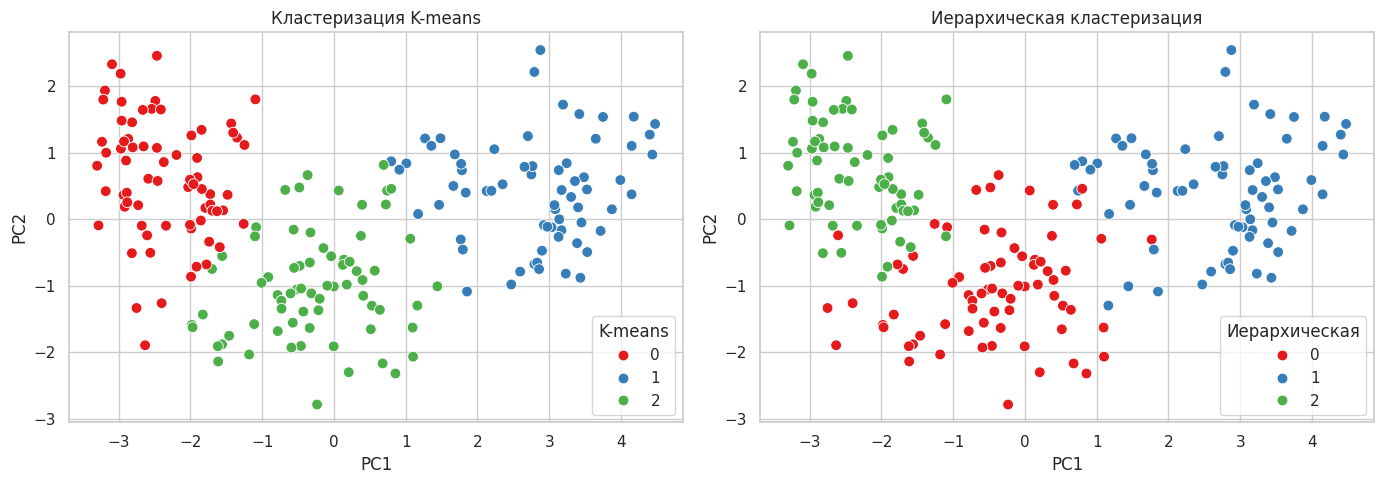

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='K-means',
    palette='Set1',
    s=60,
    ax=axes[0]
)
axes[0].set_title('Кластеризация K-means')

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Иерархическая',
    palette='Set1',
    s=60,
    ax=axes[1]
)
axes[1].set_title('Иерархическая кластеризация')

plt.tight_layout()
plt.show()

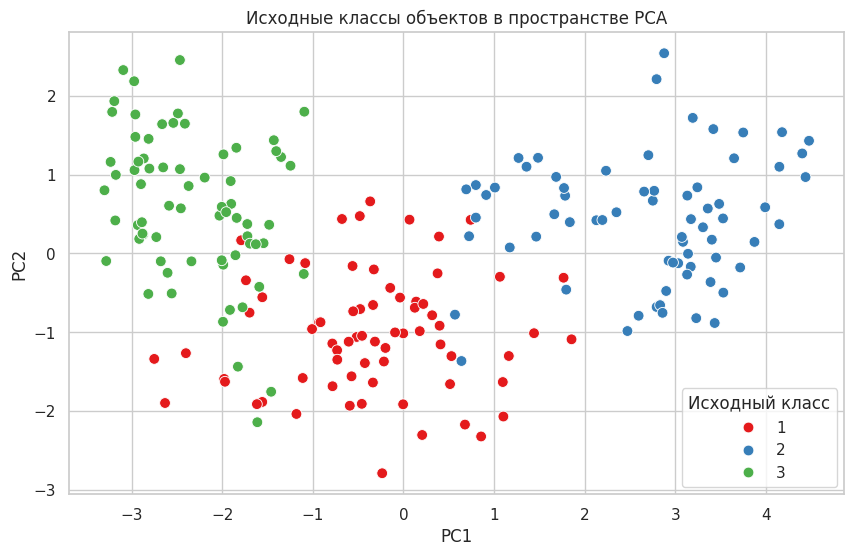

In [147]:
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Исходный класс',
    palette='Set1',
    s=60
)

plt.title('Исходные классы объектов в пространстве PCA')
plt.show()

В ходе кластерного анализа были выделены три кластера объектов. Для оценки качества разбиения использовались методы K-means и иерархической кластеризации, результаты которых сравнивались с исходными классами объектов в пространстве главных компонент (PCA).

Визуальный анализ показывает, что оба алгоритма успешно выявляют три устойчивые группы данных. Кластеры хорошо разделены в пространстве первых двух главных компонент, что свидетельствует о наличии естественной трехкластерной структуры в выборке.

Результаты метода K-means практически полностью соответствуют исходному распределению классов: левый, центральный и правый кластеры корректно идентифицированы, а число ошибочно отнесённых объектов минимально. То же самое можно наблюдать и в иерархическом разбиении, которое также получилось почти идельаным визуально.

Сравнение с истинными метками классов показывает, что значение k = 3 выбрано корректно, поскольку полученные кластеры хорошо согласуются с реальной структурой данных. Наиболее отчётливо выделяется правый кластер, который практически полностью отделён от остальных, тогда как некоторое перекрытие наблюдается между левым и центральным классами.

Таким образом, результаты кластеризации подтверждают наличие в данных трёх естественных групп объектов, а метод K-means демонстрирует немного более точное соответствие исходным классам по сравнению с иерархической кластеризацией. Это позволяет считать разбиение на 3 кластера адекватным и информативным для дальнейшего анализа данных.

## Возврат к исходным единицам измерения.

In [148]:
kmeans_centers_original = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns,
    index=['Кластер 0', 'Кластер 1', 'Кластер 2']
)

hierarchical_profile = X.groupby(
    pd.Series(hierarchical_labels, index=X.index, name='cluster')
).mean()

hierarchical_profile.index = [
    f'Кластер {i}' for i in hierarchical_profile.index
]

combined_profile = pd.concat(
    [
        kmeans_centers_original.assign(Метод='K-means'),
        hierarchical_profile.assign(Метод='Иерархическая')
    ]
)

combined_profile = combined_profile.set_index(
    'Метод', append=True
).swaplevel(0, 1)

display(combined_profile.round(3))

area  perimeter  compactness  length  width  \
Метод                                                                    
K-means       Кластер 0  11.857     13.248        0.848   5.232  2.850   
              Кластер 1  18.495     16.203        0.884   6.176  3.698   
              Кластер 2  14.438     14.338        0.882   5.515  3.259   
Иерархическая Кластер 0  14.199     14.234        0.879   5.478  3.226   
              Кластер 1  18.371     16.145        0.884   6.158  3.685   
              Кластер 2  11.872     13.257        0.848   5.239  2.849   

                         asymmetry  groove_length  
Метод                                              
K-means       Кластер 0      4.742          5.102  
              Кластер 1      3.632          6.042  
              Кластер 2      2.707          5.121  
Иерархическая Кластер 0      2.612          5.086  
              Кластер 1      3.639          6.017  
              Кластер 2      4.949          5.122

Для содержательной интерпретации результатов центры кластеров были преобразованы обратно в исходные единицы измерения с помощью обратного преобразования StandardScaler. Это позволило оценить средние характеристики семян в каждом кластере без использования стандартизированных значений.

По результатам K-means кластер 0 объединяет преимущественно небольшие семена. Средняя площадь составляет 11,857, периметр — 13,248, длина — 5,232, ширина — 2,850. Для этой группы также характерны сравнительно низкая компактность (0,848) и коэффициент асимметрии 2,850.

Кластер 1 содержит наиболее крупные семена: средняя площадь составляет 18,495, периметр — 16,203, длина — 6,176, ширина — 3,698. Кроме того, эта группа характеризуется наибольшей средней длиной бороздки (6,042) и относительно высокой компактностью (0,884).

Кластер 2 занимает промежуточное положение по размерным характеристикам. Средняя площадь семян составляет 14,438, периметр — 14,338, длина — 5,515, ширина — 3,259. Компактность близка к значению второго кластера (0,882), а коэффициент асимметрии является наименьшим среди трёх групп (2,707).

Иерархическая кластеризация выявила аналогичное разделение. Кластер 1 объединяет наиболее крупные семена, кластер 2 — наиболее мелкие, а кластер 0 занимает промежуточное положение по площади, периметру, длине и ширине. Таким образом, содержательные характеристики групп, выделенных двумя методами, в целом совпадают, хотя номера кластеров различаются.

Наиболее существенными признаками для описания выделенных групп являются площадь, периметр, длина и ширина семян. Они позволяют разделить объекты по размерным характеристикам на крупные, средние и небольшие семена. Дополнительную информацию о форме семян предоставляют компактность и коэффициент асимметрии.

Таким образом, обратное преобразование позволило перейти от абстрактных стандартизированных характеристик к физическим параметрам семян. Оба метода выявили сходную структуру данных и сформировали три группы, различающиеся прежде всего размерами семян и некоторыми особенностями их формы.

# Заключение.

В ходе работы были реализованы два метода кластеризации: K-means и иерархическая кластеризация с использованием метода Уорда. Для обоих алгоритмов было выбрано разбиение на три кластера, что соответствует количеству разновидностей семян, представленных в исходном наборе данных Seeds. Перед выполнением кластеризации числовые признаки были стандартизированы с помощью StandardScaler, поскольку оба метода используют расстояния между объектами и чувствительны к различиям в масштабах признаков.

По результатам оценки внутренних метрик K-means показал несколько лучшие результаты. Значение Silhouette Score составило 0,4007 против 0,3926 у иерархической кластеризации, а Calinski-Harabasz — 249,7842 против 238,3612. Это свидетельствует о несколько лучшей компактности и разделённости кластеров при использовании K-means. По метрике Davies-Bouldin преимущество также оказалось у K-means: 0,9279 против 0,9445, поскольку для данной метрики меньшие значения соответствуют лучшему качеству кластеризации.

По внешним метрикам более высокие результаты продемонстрировала иерархическая кластеризация. Значения ARI составили 0,7970 против 0,7733 у K-means, NMI — 0,7498 против 0,7279, Rand Index — 0,9102 против 0,8997. Это указывает на несколько более высокое соответствие результатов иерархической кластеризации исходным разновидностям семян.

По количеству объектов полученные кластеры оказались достаточно равномерными. K-means сформировал группы размером 72, 67 и 71 объект, а иерархическая кластеризация — 73, 70 и 67 объектов. Различия в размерах кластеров между методами незначительны.

Интерпретация центров кластеров в исходных единицах измерения показала, что оба метода выделяют три группы, различающиеся преимущественно размерными характеристиками семян. Первая группа объединяет преимущественно небольшие семена с относительно низкими значениями площади, периметра, длины и ширины. Вторая группа характеризуется наиболее высокими значениями этих признаков и соответствует группе крупных семян. Третья группа занимает промежуточное положение по размерным характеристикам. Дополнительную информацию о форме семян предоставляют компактность, коэффициент асимметрии и длина бороздки.

Расстояния между центрами кластеров подтверждают наличие различий между выделенными группами. В обоих методах наиболее отчётливо выделяется группа крупных семян, которая находится на значительном расстоянии от группы небольших семян. Анализ внутрикластерного разброса также показал сопоставимую компактность результатов. При этом суммарная внутрикластерная сумма квадратов у K-means составила 430,6590, а у иерархической кластеризации — 445,0493. Это свидетельствует о несколько меньшем общем разбросе объектов внутри кластеров K-means.

Оба метода показали применимость к рассматриваемому набору данных, поскольку Seeds содержит числовые признаки, описывающие геометрические характеристики семян. K-means хорошо подходит для выделения компактных групп и отличается простотой настройки и интерпретации. Однако его результат зависит от выбора количества кластеров и начального расположения центроидов. Иерархическая кластеризация позволяет дополнительно исследовать структуру данных с помощью дендрограммы и не требует случайной инициализации центров, однако её результаты зависят от выбранного способа объединения кластеров и метрики расстояния.

По совокупности результатов нельзя однозначно выделить существенно превосходящий метод. K-means показал небольшое преимущество по внутренним метрикам и общей внутрикластерной сумме квадратов, тогда как иерархическая кластеризация обеспечила более высокое соответствие исходным классам. Оба алгоритма сформировали сходную по содержанию структуру данных и позволили выделить группы семян с различными размерными характеристиками.

Таким образом, для данного набора данных оба метода являются подходящими. Если основной целью является формирование компактных и хорошо разделённых групп, предпочтение можно отдать K-means. Если важнее соответствие полученных кластеров исходным разновидностям семян и исследование иерархической структуры данных, целесообразно использовать метод Уорда.

# Список использованных источников.

1. Seeds Dataset : набор данных для кластеризации [Электронный ресурс] // Kaggle : платформа для работы с данными и машинного обучения. — URL: https://www.kaggle.com/datasets/rwzhang/seeds-dataset (дата обращения: 12.11.2026). — Текст : электронный.

2. Антонянц Е. Н., Искусственный интеллект и машинное обучение : лекция по дисциплине. — Новосибирск : НГТУ НЭТИ, 13 октября 2026 г.